In [63]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import datetime as dt


low_rate_data_path = "BlRv_SN0112 LR_06-07-2026_12_56_38.csv"
high_rate_data_path = "BlRv_SN0112 HR_06-07-2026_12_56_38.csv"

gps_data_path = "2025-06-07-Log(1).csv"
gps_logged_data_path = "ABJ SUS _06-07-2026_12_57_11.csv"
telemetrum_data_path = "2026-06-07-serial-17455-flight-0006.csv"


LRdata = pd.read_csv(low_rate_data_path)
HRdata = pd.read_csv(high_rate_data_path)
GPSdata = pd.read_csv(gps_data_path)
GPSLOGGEDdata = pd.read_csv(gps_logged_data_path)
TELEMETRUMdata =pd.read_csv(telemetrum_data_path)
#print(LRdata)

print(HRdata.columns)
print(LRdata.columns)
print(GPSdata.columns)
print(GPSLOGGEDdata.columns)
print(TELEMETRUMdata.columns)
plt.style.use('dark_background')


Index(['Year', 'Month', 'Day', 'Time', 'Flight_Time_(s)', 'Sync', 'Gyro_X',
       'Gyro_Y', 'Gyro_Z', 'Accel_X', 'Accel_Y', 'Accel_Z', 'Quat_1', 'Quat_2',
       'Quat_3', 'Quat_4', 'Aux_Volts', 'Current'],
      dtype='str')
Index(['Year', 'Month', 'Day', 'Time', 'Flight_Time_(s)', 'Sync',
       'Temperature_(F)', 'Baro_Press_(atm)', 'Baro_Altitude_ASL_(feet)',
       'Baro_Altitude_AGL_(feet)',
       ...
       'GT_FUTANG.3', 'LT_TVAL1.3', 'GT_TVAL2.3', 'LT_VEL1.3', 'GT_VEL2.3',
       'LT_BVEL1.3', 'GT_BURN.3', 'Armed.3', 'Reserved.7', 'Reserved.8'],
      dtype='str', length=101)
Index(['TRACKER', 'DATE', 'TIME', 'LAT', 'LON', 'ALT', 'FIX', 'HORZV', 'VERTV',
       'HEAD', 'FLAGS', '#TOT', '>40', '>32', '>24', 'RSSI', 'BATT'],
      dtype='str')
Index(['UTCTIME', 'UNIXTIME', 'ALT', 'LAT', 'LON', '#SATS', 'FIX', 'HORZV',
       'VERTV', 'HEAD', 'FLAGS', '>40', '>32', '>24', 'RSSI', 'BATT',
       'Altitude AGL', 'Launch detection', 'Apogee detection',
       'Landing detection', 

Open-Meteo request: https://historical-forecast-api.open-meteo.com/v1/forecast?latitude=35.3466&longitude=-117.809&timezone=US%2FPacific&start_hour=2026-06-07T12%3A00&end_hour=2026-06-07T12%3A00&timeformat=iso8601&temperature_unit=celsius&wind_speed_unit=ms&hourly=surface_pressure%2Ctemperature_2m%2Cwind_speed_10m%2Cwind_direction_10m%2Ctemperature_1000hPa%2Cwind_speed_1000hPa%2Cwind_direction_1000hPa%2Cgeopotential_height_1000hPa%2Ctemperature_975hPa%2Cwind_speed_975hPa%2Cwind_direction_975hPa%2Cgeopotential_height_975hPa%2Ctemperature_950hPa%2Cwind_speed_950hPa%2Cwind_direction_950hPa%2Cgeopotential_height_950hPa%2Ctemperature_925hPa%2Cwind_speed_925hPa%2Cwind_direction_925hPa%2Cgeopotential_height_925hPa%2Ctemperature_900hPa%2Cwind_speed_900hPa%2Cwind_direction_900hPa%2Cgeopotential_height_900hPa%2Ctemperature_850hPa%2Cwind_speed_850hPa%2Cwind_direction_850hPa%2Cgeopotential_height_850hPa%2Ctemperature_800hPa%2Cwind_speed_800hPa%2Cwind_direction_800hPa%2Cgeopotential_height_800hPa%2

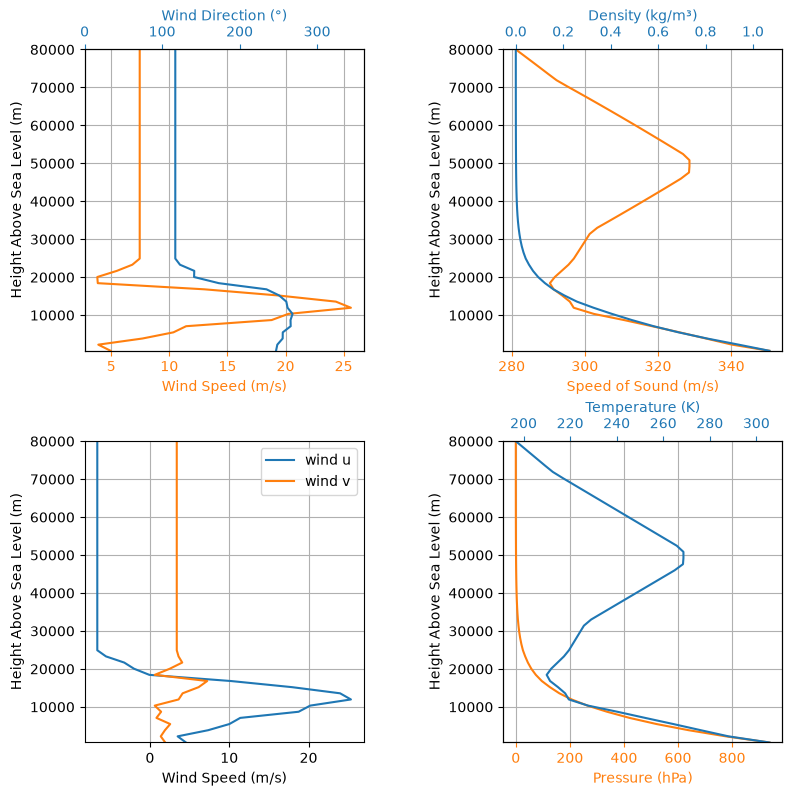

In [1]:
from openmeteo_environment import create_openmeteo_environment


# Fetch the historical Open-Meteo profile for the JUMP flight and build RocketPy's Environment.
# Open-Meteo pressure-level data is hourly, so use the weather hour nearest launch.
LAUNCH_LATITUDE = 35.3466
LAUNCH_LONGITUDE = -117.809
LAUNCH_ELEVATION_M = 609.57
LAUNCH_DATE = "2026-06-07"
LAUNCH_WEATHER_HOUR = "12:00"
LAUNCH_TIMEZONE = "US/Pacific"

openmeteo_result = create_openmeteo_environment(
    LAUNCH_LATITUDE,
    LAUNCH_LONGITUDE,
    LAUNCH_DATE,
    LAUNCH_WEATHER_HOUR,
    timezone_name=LAUNCH_TIMEZONE,
    elevation_m=LAUNCH_ELEVATION_M,
    endpoint="historical",
    max_expected_height_m=80000.0,
)

env = openmeteo_result.environment

print(f"Open-Meteo request: {openmeteo_result.request_url}")
print(f"Model top before extension: {openmeteo_result.model_top_height_m:.1f} m ASL")
print(f"Pressure points: {len(openmeteo_result.pressure)}")
print(f"Temperature points: {len(openmeteo_result.temperature)}")
print(f"Wind points: {len(openmeteo_result.wind_u)}")

env.plots.atmospheric_model()


In [4]:
NormalizedVelocity = np.sqrt((LRdata['Velocity_Up']*LRdata['Velocity_Up'])+((LRdata['Velocity_DR']*LRdata['Velocity_DR']))+(LRdata['Velocity_CR']*LRdata['Velocity_CR']))
MachNumber = (NormalizedVelocity/3.281)/(env.speed_of_sound(LRdata['Inertial_Altitude']/3.281))


MissionTimeLR = LRdata['Flight_Time_(s)']
MissionTimeHR = HRdata['Flight_Time_(s)']

#Integrate velocity
timecutoff = 7.46

# X_accel_icareabout = HRdata[HRdata['Flight_Time_(s)'] < timecutoff]['Accel_X']
# Velocity_X = np.trapezoid(X_accel_icareabout*9.8065,dx=0.002)
# print(X_accel_icareabout[-1:])
# print(Velocity_X)

# Y_accel_icareabout = HRdata[HRdata['Flight_Time_(s)'] < timecutoff]['Accel_Y']
# Velocity_Y = np.trapezoid((Y_accel_icareabout*9.8065)-9.81,dx=0.002)
# print(Y_accel_icareabout[-1:])
# print(Velocity_Y)

# Z_accel_icareabout = HRdata[HRdata['Flight_Time_(s)'] < timecutoff]['Accel_Z']
# Velocity_Z = np.trapezoid(Z_accel_icareabout*9.8065,dx=0.002)
# print(Z_accel_icareabout[-1:])
# print(Velocity_Z)

# NormalizedRecalcedVelocity = np.sqrt((Velocity_X**2)+(Velocity_Y**2)+(Velocity_Z**2))
# print(NormalizedRecalcedVelocity*3.281)

# maxvalt = LRdata[LRdata['Flight_Time_(s)'] == timecutoff ]['Baro_Altitude_AGL_(feet)']/3.281
# print("max v alt= " + str(maxvalt))

#maxmach = NormalizedRecalcedVelocity/env.speed_of_sound(maxvalt)
#print(maxmach)


#TO DO
AxialAcceleration = np.sqrt((HRdata['Accel_X']**2) + (HRdata['Accel_Y']**2) + (HRdata['Accel_Z']**2))


#


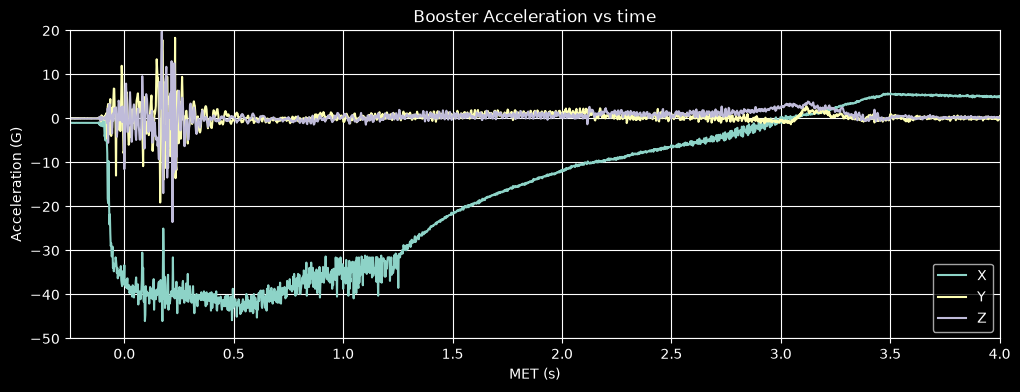

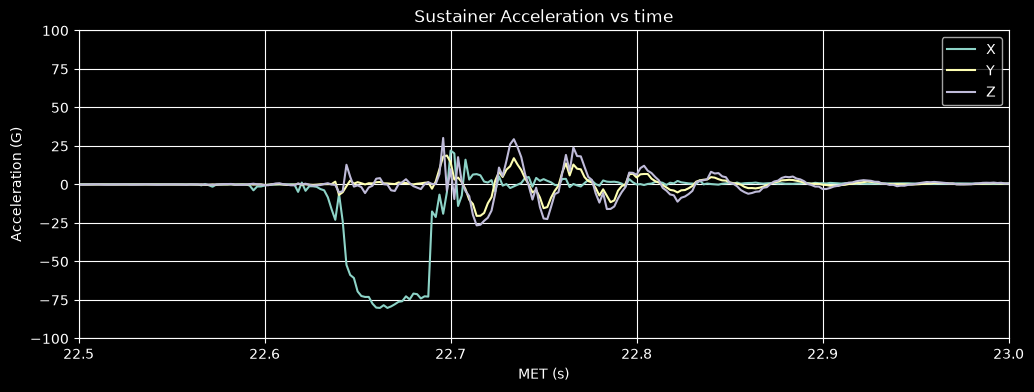

In [15]:
#plot motor accel
fig, ax = plt.subplots()

ax.plot('Flight_Time_(s)','Accel_X',data=HRdata,label="X")
ax.plot('Flight_Time_(s)','Accel_Y',data=HRdata,label="Y")
ax.plot('Flight_Time_(s)','Accel_Z',data=HRdata,label="Z")

ax.set(xlabel='MET (s)', ylabel='Acceleration (G)',
       title='Booster Acceleration vs time')
ax.grid()

ax.set_xlim(-0.25,4)
ax.set_ylim(-50,20)
ax.legend()

fig.set_size_inches(12,4)


#SUSTAINER
fig, ax = plt.subplots()

ax.plot('Flight_Time_(s)','Accel_X',data=HRdata,label="X")
ax.plot('Flight_Time_(s)','Accel_Y',data=HRdata,label="Y")
ax.plot('Flight_Time_(s)','Accel_Z',data=HRdata,label="Z")

ax.set(xlabel='MET (s)', ylabel='Acceleration (G)',
       title='Sustainer Acceleration vs time')
ax.grid()

ax.set_xlim(22.5,23)
ax.set_ylim(-100,100)
ax.legend()

fig.set_size_inches(12,4)

In [ ]:
#Write an altus metrum eeprom decoder 

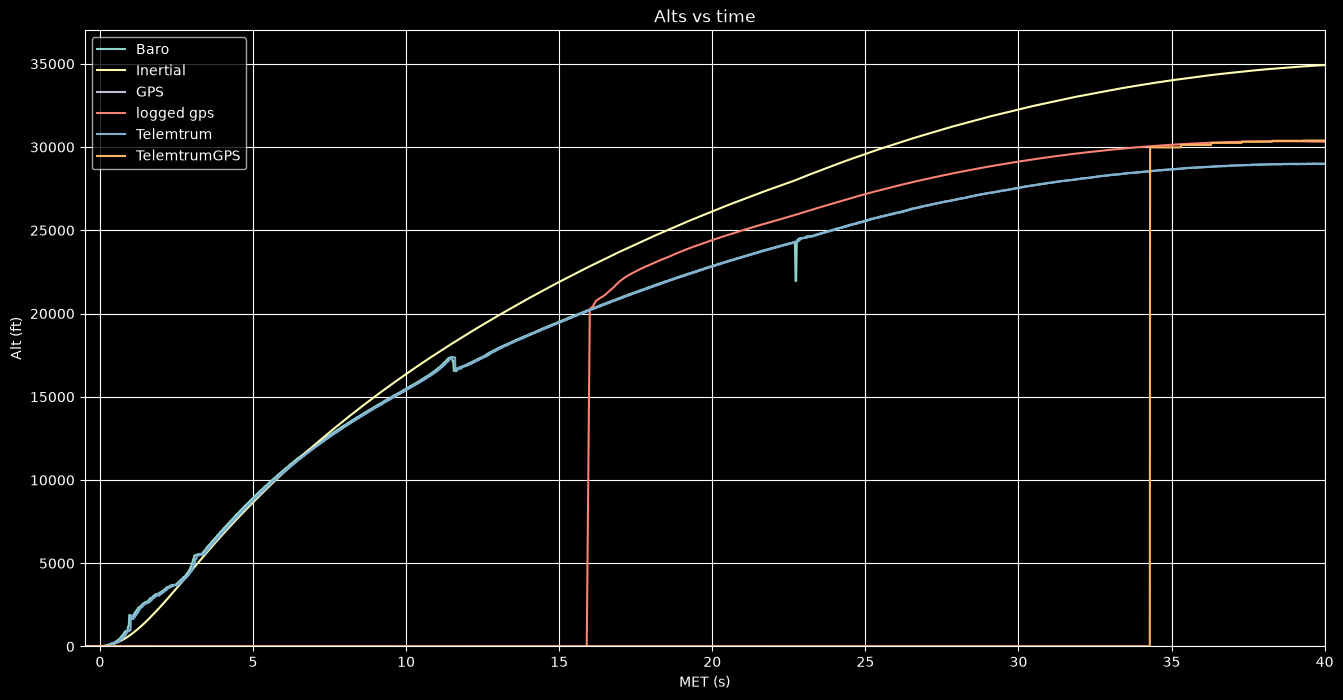

In [89]:

fig, ax = plt.subplots()



GPStime = pd.to_datetime(GPSdata['DATE']+ " " + GPSdata['TIME'], format='%Y-%m-%d %H:%M:%S.%f')
#print(GPStime)
launchalt = GPSdata['ALT'][0]
Launchtime = dt.datetime(2026,6,7,12,57,34)

GPStimeadj = GPStime-Launchtime
GPSmissiontime = GPStimeadj.astype('timedelta64[s]')

GPSLOGGEDtime = GPSLOGGEDdata['UNIXTIME']
#print(GPStime)
LOGGEDlaunchalt = GPSLOGGEDdata['ALT'][0]
LOGGEDLaunchtime = 1783479415.7

GPSLOGGEDtimeadj = GPSLOGGEDtime-LOGGEDLaunchtime

# print(GPSLOGGEDtimeadj)
# print(GPSLOGGEDdata['ALT'])

Metrumalt = TELEMETRUMdata['height']*3.281
Metrumgpsalt = (TELEMETRUMdata['altitude.1']*3.281)-2000

ax.plot('Flight_Time_(s)','Baro_Altitude_AGL_(feet)',data=LRdata,label="Baro")
ax.plot('Flight_Time_(s)','Inertial_Altitude',data=LRdata, label="Inertial")
ax.plot(GPSmissiontime,GPSdata['ALT']-launchalt,label="GPS")
ax.plot(GPSLOGGEDtimeadj,GPSLOGGEDdata['ALT']-LOGGEDlaunchalt,label="logged gps")
ax.plot(TELEMETRUMdata['time'],Metrumalt, label='Telemtrum')
ax.plot(TELEMETRUMdata['time'],Metrumgpsalt, label='TelemtrumGPS')

ax.set(xlabel='MET (s)', ylabel='Alt (ft)',
       title='Alts vs time')
ax.grid()
ax.set_ylim(0,37000)
ax.set_xlim(-0.5,40)
ax.legend()
fig.set_size_inches(16,8)

In [65]:
def getQ(velocity,altitude):
    currentq = ((velocity*velocity)*env.density(altitude))
    return currentq/2

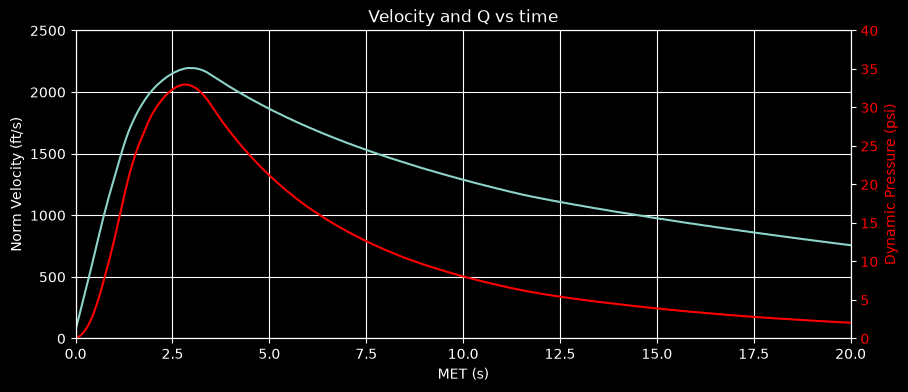

In [67]:
#absolute velocity
fig, ax = plt.subplots()

altitudes = LRdata['Inertial_Altitude']

dynamicpressure = (getQ(NormalizedVelocity/3.281,altitudes/3.281)/6895)


ax.plot(MissionTimeLR,NormalizedVelocity)

ax.set(xlabel='MET (s)', ylabel='Norm Velocity (ft/s)',
       title='Velocity and Q vs time')
ax.set_xlim(0,20)
ax.set_ylim(0,2500)
ax.grid()

ax2 = ax.twinx()
ax2.set_ylabel("Dynamic Pressure (psi)",color="red")
ax2.plot(MissionTimeLR,dynamicpressure,color = "red")
ax2.tick_params(axis='y', labelcolor="red")
ax2.set_ylim(0,40)

fig.set_size_inches(10,4)

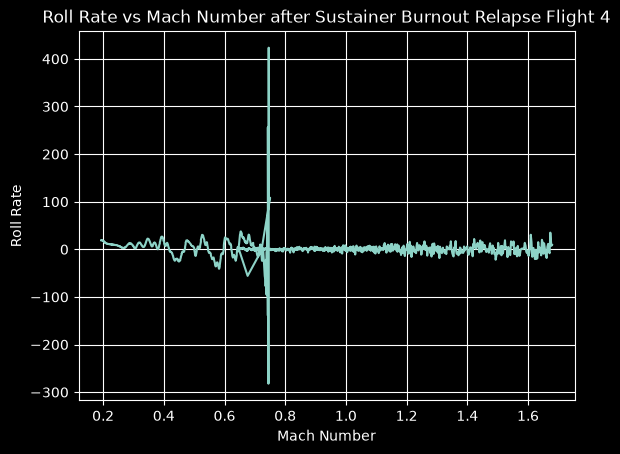

Max Mach after burnout: 1.679275876365543


In [ ]:
#roll rate vs mach 

def rollrate_on_mach_timescale(roll_time, roll_rate, mach_time, mach_number, sustainer_burnout_time):
    """
    Resample roll_rate onto the MachNumber time base after sustainer burnout.

    Returns:
        mach_after_burnout, rollrate_after_burnout, time_after_burnout
    """
    roll_time = np.asarray(roll_time)
    roll_rate = np.asarray(roll_rate)
    
    mach_time = np.asarray(mach_time)
    mach_number = np.asarray(mach_number)

    # Keep only Mach samples after sustainer burnout
    lowermask = mach_time >= sustainer_burnout_time
    time_after_burnout = mach_time[lowermask]
    mach_after_burnout = mach_number[lowermask]

    uppermask = time_after_burnout <= 40
    time_after_burnout = time_after_burnout[uppermask]
    mach_after_burnout = mach_after_burnout[uppermask]

    # Interpolate roll rate onto MachNumber timestamps
    rollrate_after_burnout = np.interp(
        time_after_burnout,
        roll_time,
        roll_rate
    )

    return mach_after_burnout, rollrate_after_burnout, time_after_burnout

fig, ax = plt.subplots()

mach_burnout, roll_burnout, t_burnout = rollrate_on_mach_timescale(
    HRdata['Flight_Time_(s)'],
    HRdata['Gyro_Y'],
    LRdata['Flight_Time_(s)'],
    MachNumber,
    5
)

plt.plot(mach_burnout, roll_burnout)
plt.xlabel("Mach Number")
plt.ylabel("Roll Rate")
plt.title("Roll Rate vs Mach Number after Sustainer Burnout Relapse Flight 4")
plt.grid(True)
plt.show()

fig.set_size_inches(14,4)

print("Max Mach after burnout:", np.max(mach_burnout))

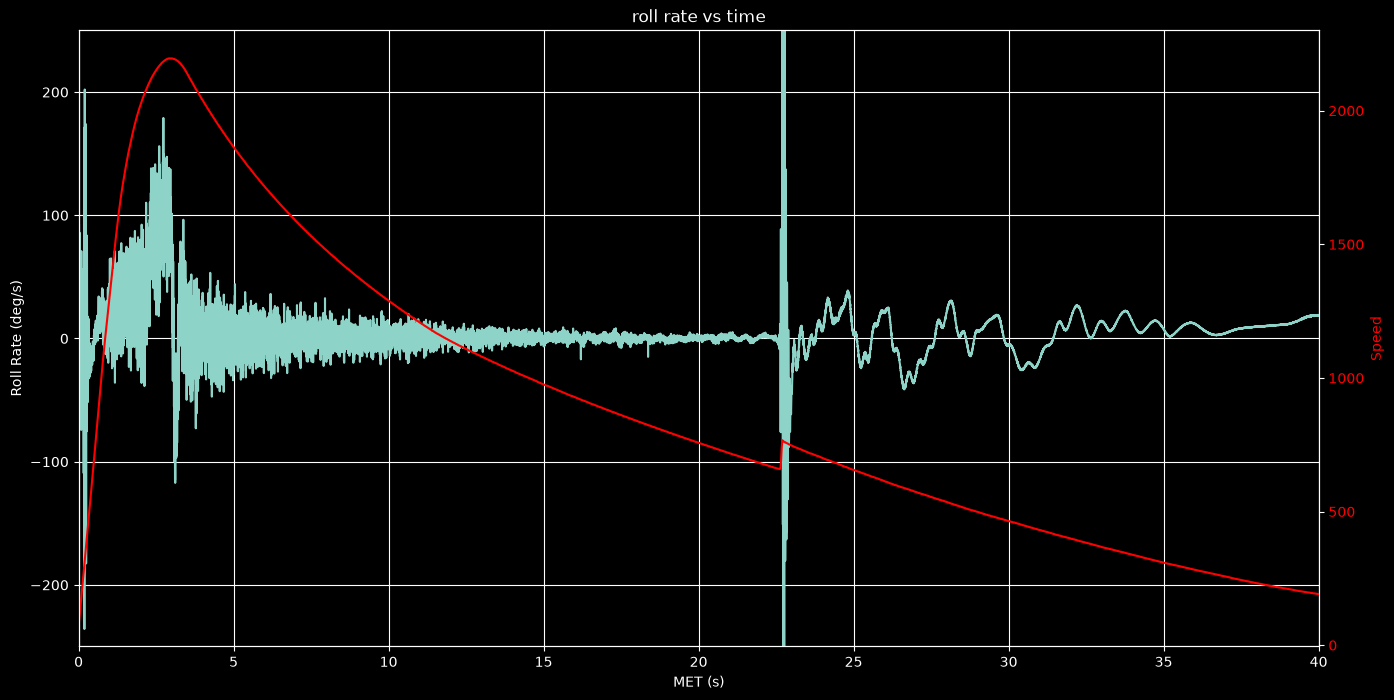

In [81]:
#roll rate vs mach 
fig, ax = plt.subplots()

ax.plot('Flight_Time_(s)','Gyro_Y',data=HRdata,label="RollRate")


ax.set(xlabel='MET (s)', ylabel='Roll Rate (deg/s)',
       title='roll rate vs time')
ax.set_xlim(0,40)
ax.set_ylim(-250,250)
ax.grid()

ax2 = ax.twinx()
ax2.set_ylabel("Speed",color="red")
ax2.plot(LRdata['Flight_Time_(s)'],NormalizedVelocity,label="S",color="Red")
ax2.tick_params(axis='y', labelcolor="red")
ax2.set_ylim(-5,2300)


fig.set_size_inches(16,8)

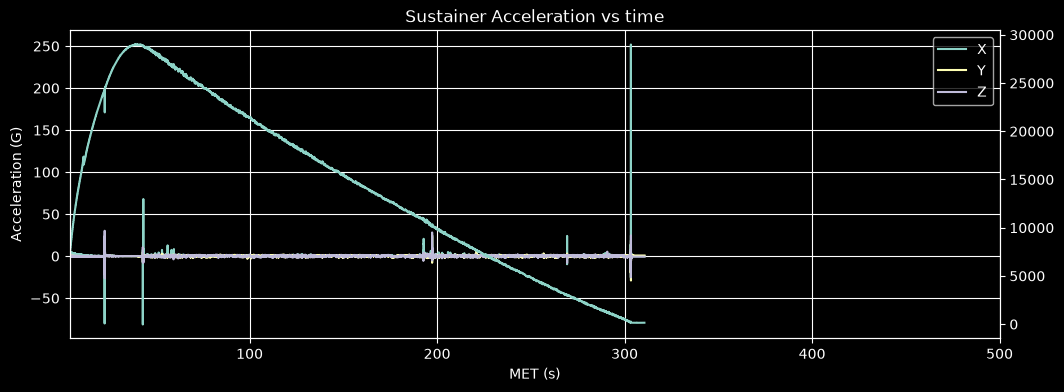

In [71]:
#SUSTAINER
fig, ax = plt.subplots()

ax.plot('Flight_Time_(s)','Accel_X',data=HRdata,label="X")
ax.plot('Flight_Time_(s)','Accel_Y',data=HRdata,label="Y")
ax.plot('Flight_Time_(s)','Accel_Z',data=HRdata,label="Z")

ax.set(xlabel='MET (s)', ylabel='Acceleration (G)',
       title='Sustainer Acceleration vs time')
ax.grid()

ax2 = ax.twinx()
ax2.plot('Flight_Time_(s)','Baro_Altitude_AGL_(feet)',data=LRdata,label="Baro")

ax.set_xlim(4,500)
# ax.set_ylim(-20,50)
ax.legend()

fig.set_size_inches(12,4)

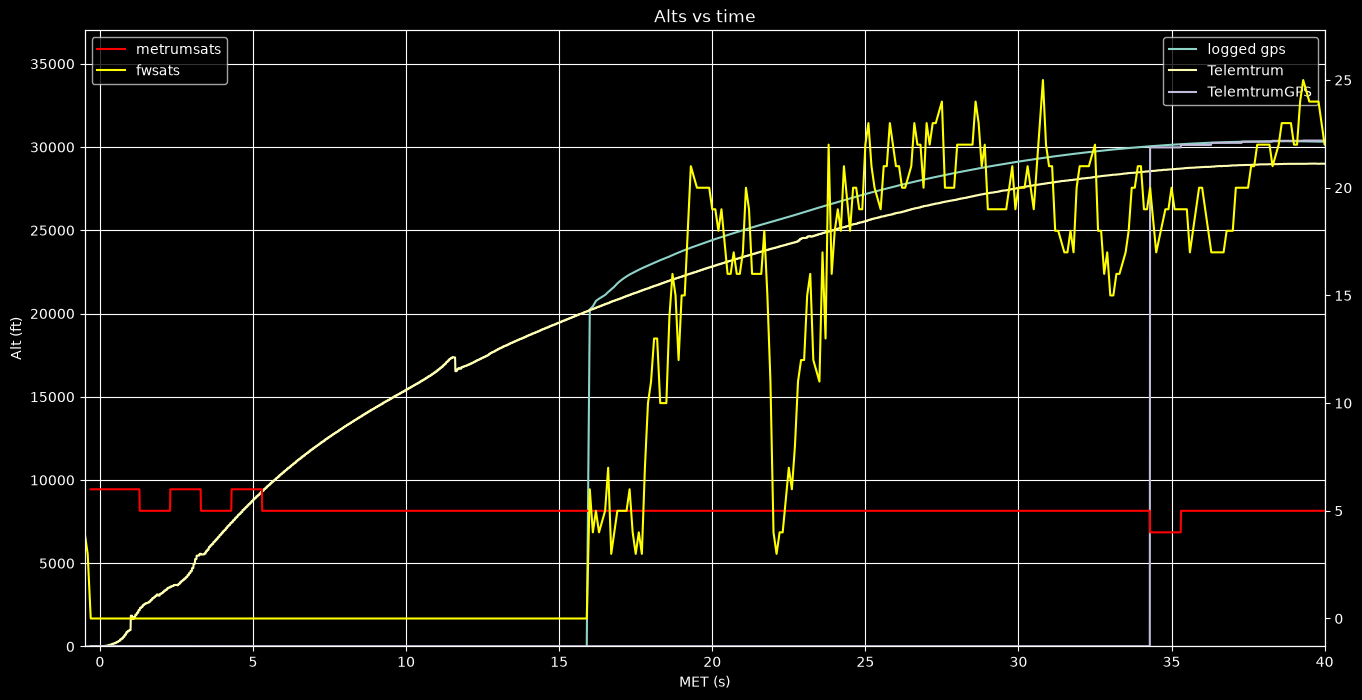

In [88]:

fig, ax = plt.subplots()



GPStime = pd.to_datetime(GPSdata['DATE']+ " " + GPSdata['TIME'], format='%Y-%m-%d %H:%M:%S.%f')
#print(GPStime)
launchalt = GPSdata['ALT'][0]
Launchtime = dt.datetime(2026,6,7,12,57,34)

GPStimeadj = GPStime-Launchtime
GPSmissiontime = GPStimeadj.astype('timedelta64[s]')

GPSLOGGEDtime = GPSLOGGEDdata['UNIXTIME']
#print(GPStime)
LOGGEDlaunchalt = GPSLOGGEDdata['ALT'][0]
LOGGEDLaunchtime = 1783479415.7

GPSLOGGEDtimeadj = GPSLOGGEDtime-LOGGEDLaunchtime

# print(GPSLOGGEDtimeadj)
# print(GPSLOGGEDdata['ALT'])

Metrumalt = TELEMETRUMdata['height']*3.281
Metrumgpsalt = (TELEMETRUMdata['altitude.1']*3.281)-2000


totalFWsats = GPSLOGGEDdata['>40'] + GPSLOGGEDdata['>32'] + GPSLOGGEDdata['>24']

ax.plot(GPSLOGGEDtimeadj,GPSLOGGEDdata['ALT']-LOGGEDlaunchalt,label="logged gps")
ax.plot(TELEMETRUMdata['time'],Metrumalt, label='Telemtrum')
ax.plot(TELEMETRUMdata['time'],Metrumgpsalt, label='TelemtrumGPS')

ax.set(xlabel='MET (s)', ylabel='Alt (ft)',
       title='Alts vs time')
ax.grid()
ax.set_ylim(0,37000)
ax.set_xlim(-0.5,40)
ax.legend()

ax2 = ax.twinx()
ax2.plot(TELEMETRUMdata['time'],TELEMETRUMdata['nsat'], label="metrumsats",color='red')
ax2.plot(GPSLOGGEDtimeadj,totalFWsats, label="fwsats",color='yellow')
ax2.legend()
fig.set_size_inches(16,8)